# 03 : analyse

Agrégations, jointure, analyse dans le temps et visualisations, à partir des fichiers nettoyés par `02_nettoyage.ipynb`. Une section par question, chacune terminée par une réponse.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

articles = pd.read_csv("../data/processed/articles.csv", parse_dates=["created_at"])
modeles = pd.read_csv("../data/processed/modeles.csv", parse_dates=["publication_date"])

BLEU = "#2a78d6"
ORANGE = "#eb6834"
GRIS = "#a3a29c"
SORTIE_CHATGPT = pd.Timestamp("2022-11-30", tz="UTC")

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

## 1. Comment la part de l'IA dans les sujets populaires de Hacker News a-t-elle évolué mois par mois depuis 2020 ?

On compte, chaque mois, la part des articles populaires dont le titre parle d'IA (colonne `parle_ia`, construite au nettoyage). Une part plutôt qu'un nombre : le nombre d'articles varie d'une année à l'autre et 2026 s'arrête au 24 avril.

In [2]:
part_ia_par_mois = articles.set_index("created_at").resample("MS")["parle_ia"].mean() * 100

part_avant_chatgpt = articles.loc[articles["created_at"] < SORTIE_CHATGPT, "parle_ia"].mean() * 100
part_apres_chatgpt = articles.loc[articles["created_at"] >= SORTIE_CHATGPT, "parle_ia"].mean() * 100

print(f"Avant ChatGPT : {part_avant_chatgpt:.1f} %, après : {part_apres_chatgpt:.1f} %, soit {part_apres_chatgpt / part_avant_chatgpt:.1f} fois plus")
print(f"Mois record : {part_ia_par_mois.idxmax():%m/%Y}, avec {part_ia_par_mois.max():.1f} %")
part_ia_par_mois["2022-09":"2023-04"].round(1)

Avant ChatGPT : 1.5 %, après : 9.4 %, soit 6.1 fois plus
Mois record : 02/2026, avec 15.7 %


created_at
2022-09-01 00:00:00+00:00     3.7
2022-10-01 00:00:00+00:00     2.4
2022-11-01 00:00:00+00:00     2.7
2022-12-01 00:00:00+00:00     5.8
2023-01-01 00:00:00+00:00     5.4
2023-02-01 00:00:00+00:00     8.2
2023-03-01 00:00:00+00:00    12.0
2023-04-01 00:00:00+00:00    10.5
Freq: MS, Name: parle_ia, dtype: float64

**Courbe** : c'est une évolution dans le temps d'une seule mesure.

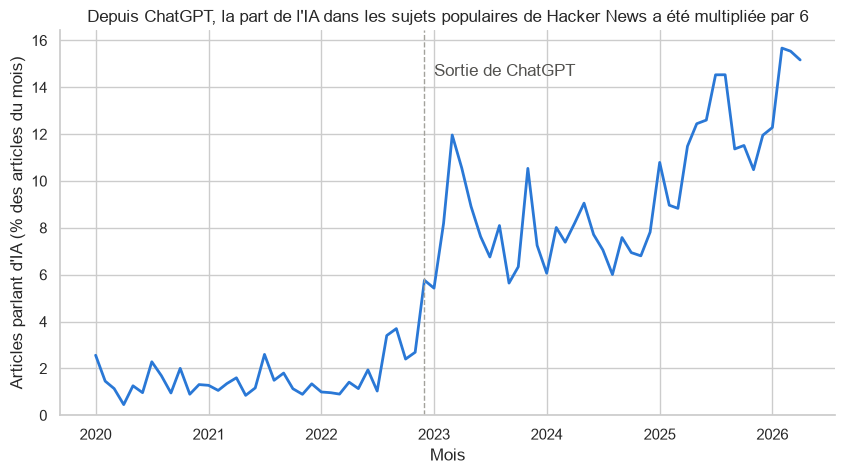

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(part_ia_par_mois.index, part_ia_par_mois.values, color=BLEU, linewidth=2)
ax.axvline(SORTIE_CHATGPT, color=GRIS, linestyle="--", linewidth=1)
ax.text(SORTIE_CHATGPT, 15, "  Sortie de ChatGPT", color="#52514e", va="top")
ax.set_title("Depuis ChatGPT, la part de l'IA dans les sujets populaires de Hacker News a été multipliée par 6")
ax.set_xlabel("Mois")
ax.set_ylabel("Articles parlant d'IA (% des articles du mois)")
ax.set_ylim(0, None)
fig.savefig("../figures/part_ia_par_mois.png", dpi=150, bbox_inches="tight")
plt.show()

**Réponse** : oui, il y a une cassure nette. De 2020 à novembre 2022, l'IA représente environ 1,5 % des articles populaires. Elle double dès décembre 2022, le mois qui suit la sortie de ChatGPT, et atteint 12 % en mars 2023 (sortie de GPT-4). Après un léger reflux en 2024, la part repart à la hausse et bat son record en février 2026, à 15,7 %. Sur l'ensemble de la période après ChatGPT, l'IA pèse 9,4 % des articles, 6 fois plus qu'avant.

## 2. Les articles sur l'IA sont-ils mieux notés et plus commentés que les autres ?

Les scores et les commentaires sont très étirés vers le haut (quelques articles dépassent 5 000) : on compare des médianes, pas des moyennes.

In [4]:
articles.groupby("parle_ia")[["score", "num_comments"]].median()

,score,num_comments
parle_ia,,
False,191.0,111.0
True,206.0,123.0


In [5]:
articles["annee"] = articles["created_at"].dt.year
commentaires_par_annee = pd.pivot_table(articles, values="num_comments", index="annee", columns="parle_ia", aggfunc="median")
score_par_annee = pd.pivot_table(articles, values="score", index="annee", columns="parle_ia", aggfunc="median")

pd.concat({"commentaires médians": commentaires_par_annee, "score médian": score_par_annee}, axis=1)

commentaires médians        score médian       
parle_ia                False  True         False  True 
annee                                                   
2020                    108.0   75.0        195.0  183.0
2021                    116.0   85.0        193.0  174.0
2022                    120.0  117.5        189.0  213.0
2023                    112.0  110.0        186.0  193.0
2024                     99.0  115.5        183.0  196.0
2025                    110.0  141.0        200.0  219.0
2026                    113.0  162.5        213.0  244.0

**Barres groupées** : on compare une mesure (le nombre médian de commentaires) entre deux catégories d'articles, année par année. La couleur ne sert qu'à distinguer l'IA du reste.

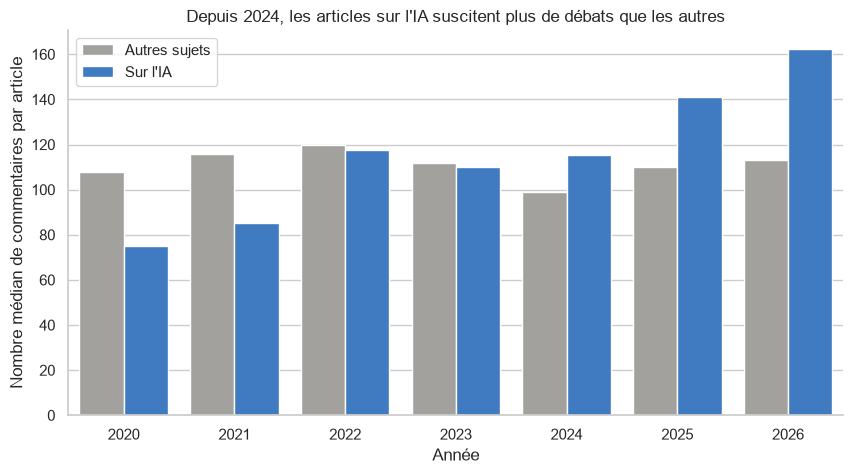

In [6]:
commentaires = (
    commentaires_par_annee.rename(columns={True: "Sur l'IA", False: "Autres sujets"})
    .reset_index()
    .melt(id_vars="annee", var_name="sujet", value_name="commentaires_medians")
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=commentaires, x="annee", y="commentaires_medians", hue="sujet",
    hue_order=["Autres sujets", "Sur l'IA"], palette={"Autres sujets": GRIS, "Sur l'IA": BLEU}, ax=ax,
)
ax.set_title("Depuis 2024, les articles sur l'IA suscitent plus de débats que les autres")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre médian de commentaires par article")
ax.legend(title=None)
fig.savefig("../figures/commentaires_ia.png", dpi=150, bbox_inches="tight")
plt.show()

**Réponse** : oui, mais seulement depuis peu, et c'est surtout vrai pour les commentaires. Sur toute la période, un article sur l'IA reçoit en médiane 123 commentaires contre 111 pour les autres, et 206 points contre 191. Mais l'écart s'est inversé : en 2020 et 2021, les articles sur l'IA étaient moins commentés que les autres (75 contre 108 en 2020). Depuis 2024, ils le sont nettement plus, jusqu'à 162 commentaires médians en 2026 contre 113. L'IA est devenue un sujet qui fait débattre.

## 3. Les sorties de modèles des grands labos provoquent-elles un pic d'articles dans les jours qui suivent ?

C'est ici que les deux jeux se rejoignent : chaque sortie de modèle d'OpenAI, Anthropic, Google ou Meta (Epoch AI) est reliée au nombre d'articles sur l'IA publiés sur Hacker News les jours qui l'entourent.

### Le nombre d'articles sur l'IA, jour par jour

In [7]:
articles_par_jour = (
    articles.assign(jour=articles["created_at"].dt.tz_localize(None).dt.normalize())
    .groupby("jour")
    .agg(articles=("id", "size"), articles_ia=("parle_ia", "sum"))
    .asfreq("D", fill_value=0)
)

articles_par_jour.loc["2023":].groupby(articles_par_jour.loc["2023":].index.day_name())["articles_ia"].mean().round(1).sort_values()

jour
Saturday     2.8
Sunday       2.9
Friday       3.7
Monday       4.2
Thursday     4.7
Wednesday    4.8
Tuesday      4.9
Name: articles_ia, dtype: float64

L'activité dépend du jour de la semaine : depuis 2023, il y a en moyenne 2,8 articles sur l'IA le samedi contre 4,9 le mardi. Or les labos publient surtout du mardi au jeudi. Pour ne pas confondre l'effet d'une sortie avec l'effet du mardi, chaque jour est comparé à **la moyenne du même jour de la semaine sur les 4 semaines précédentes**.

In [8]:
articles_par_jour["reference"] = sum(articles_par_jour["articles_ia"].shift(7 * semaine) for semaine in range(1, 5)) / 4
articles_par_jour["ecart"] = articles_par_jour["articles_ia"] - articles_par_jour["reference"]

### Les sorties de modèles

On garde les modèles des quatre grands labos publiés depuis 2023, quand l'IA occupe assez de place sur Hacker News pour qu'un pic soit visible. Les sorties **majeures** sont celles qu'Epoch AI classe comme modèles « frontière » ou « de fondation » (GPT-4, Claude 3, Gemini, Llama 3.1…).

In [9]:
GRANDS_LABOS = ["OpenAI", "Anthropic", "Google", "Meta"]
dernier_jour_couvert = articles_par_jour.index.max() - pd.Timedelta(days=7)

modeles_par_labo = modeles.assign(labo=modeles["organization"].str.split(",")).explode("labo")
sorties = modeles_par_labo[
    modeles_par_labo["labo"].isin(GRANDS_LABOS)
    & modeles_par_labo["publication_date"].between("2023-01-01", dernier_jour_couvert)
].copy()
sorties["majeure"] = (sorties["is_frontier_model"] == 1) | (sorties["is_foundation_model"] == 1)

jours_de_sortie = sorties.groupby("publication_date").agg(
    labos=("labo", lambda labos: ", ".join(sorted(set(labos)))),
    modeles=("model_name", "size"),
    majeure=("majeure", "any"),
).reset_index()

print(f"Modèles : {len(sorties)}, jours de sortie : {len(jours_de_sortie)}, dont {jours_de_sortie['majeure'].sum()} avec une sortie majeure")
jours_de_sortie[jours_de_sortie["majeure"]].tail()

Modèles : 336, jours de sortie : 228, dont 30 avec une sortie majeure


,publication_date,labos,modeles,majeure
133,2024-11-20,OpenAI,1,True
145,2025-01-29,OpenAI,1,True
152,2025-02-27,OpenAI,1,True
157,2025-03-27,OpenAI,1,True
159,2025-04-05,Meta,3,True


### La jointure

Chaque jour de sortie est étendu à une fenêtre de 7 jours avant à 7 jours après, puis joint au tableau des articles par jour. Une jointure `left` avec `validate="many_to_one"` : chaque jour de fenêtre doit trouver exactement un jour d'articles, et le nombre de lignes ne doit pas bouger.

In [10]:
decalages = pd.DataFrame({"decalage": range(-7, 8)})
fenetres = jours_de_sortie.merge(decalages, how="cross")
fenetres["jour"] = fenetres["publication_date"] + pd.to_timedelta(fenetres["decalage"], unit="D")

nb_avant = len(fenetres)
fenetres = fenetres.merge(
    articles_par_jour[["articles_ia", "reference", "ecart"]],
    left_on="jour", right_index=True, how="left", validate="many_to_one",
)
assert len(fenetres) == nb_avant

print(f"Lignes avant et après la jointure : {nb_avant}")
print(f"Jours sans correspondance : {fenetres['articles_ia'].isna().sum()}")

Lignes avant et après la jointure : 3420
Jours sans correspondance : 0


In [11]:
profil = pd.concat({
    "Sorties majeures": fenetres[fenetres["majeure"]].groupby("decalage")["ecart"].mean(),
    "Toutes les sorties": fenetres.groupby("decalage")["ecart"].mean(),
}, axis=1)

profil.round(2).T

decalage,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7
Sorties majeures,0.53,0.07,0.03,0.19,0.57,0.49,0.91,1.37,0.32,0.51,0.07,-0.06,0.71,-0.06,0.46
Toutes les sorties,0.14,-0.03,0.08,0.03,0.13,0.20,-0.06,0.23,-0.04,0.14,0.04,-0.18,0.07,0.04,0.07


**Courbe** : on suit l'écart à la normale jour par jour autour de la sortie. Les deux types de sorties partagent le même axe, en nombre d'articles.

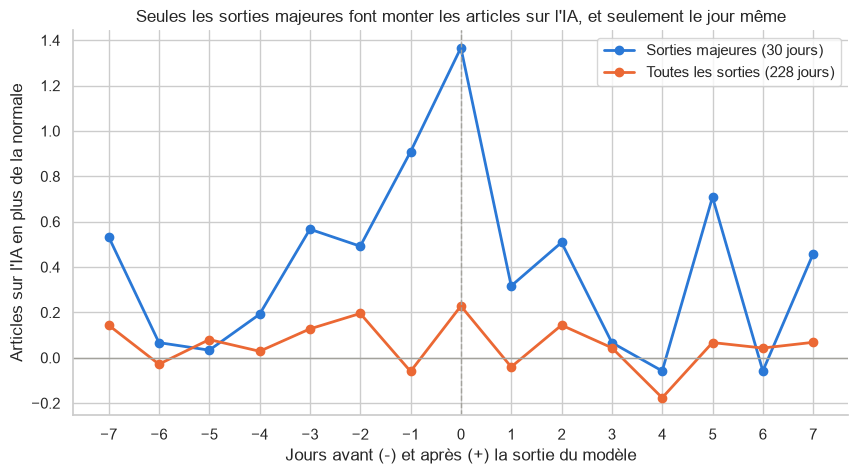

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(profil.index, profil["Sorties majeures"], color=BLEU, linewidth=2, marker="o", label="Sorties majeures (30 jours)")
ax.plot(profil.index, profil["Toutes les sorties"], color=ORANGE, linewidth=2, marker="o", label="Toutes les sorties (228 jours)")
ax.axhline(0, color=GRIS, linewidth=1)
ax.axvline(0, color=GRIS, linestyle="--", linewidth=1)
ax.set_title("Seules les sorties majeures font monter les articles sur l'IA, et seulement le jour même")
ax.set_xlabel("Jours avant (-) et après (+) la sortie du modèle")
ax.set_ylabel("Articles sur l'IA en plus de la normale")
ax.set_xticks(range(-7, 8))
ax.legend()
fig.savefig("../figures/effet_sorties.png", dpi=150, bbox_inches="tight")
plt.show()

### Le pic est-il dû au hasard ?

Avec seulement 30 sorties majeures, un pic peut apparaître par chance. On tire donc 500 fois 30 dates au hasard, en respectant le jour de la semaine de chaque vraie sortie, et on regarde à quelle fréquence le hasard produit un pic au moins aussi fort le jour même et le lendemain.

In [13]:
def ecart_moyen_jour_et_lendemain(dates):
    return np.mean([articles_par_jour["ecart"].reindex(dates + pd.Timedelta(days=jour)).mean() for jour in (0, 1)])


def tirer_meme_jour_de_semaine(dates, generateur):
    periode = articles_par_jour.loc["2023-01-01":dernier_jour_couvert].index
    return pd.DatetimeIndex([generateur.choice(periode[periode.dayofweek == date.dayofweek]) for date in dates])


generateur = np.random.default_rng(0)
for nom, dates in [
    ("Sorties majeures", pd.DatetimeIndex(jours_de_sortie.loc[jours_de_sortie["majeure"], "publication_date"])),
    ("Toutes les sorties", pd.DatetimeIndex(jours_de_sortie["publication_date"])),
]:
    observe = ecart_moyen_jour_et_lendemain(dates)
    hasard = [ecart_moyen_jour_et_lendemain(tirer_meme_jour_de_semaine(dates, generateur)) for _ in range(500)]
    print(f"{nom} : {observe:+.2f} articles, le hasard fait aussi bien dans {np.mean(np.array(hasard) >= observe):.0%} des tirages")

Sorties majeures : +0.84 articles, le hasard fait aussi bien dans 3% des tirages


Toutes les sorties : +0.09 articles, le hasard fait aussi bien dans 41% des tirages


**Réponse** : oui pour les grandes sorties, non pour les autres. Le jour d'une sortie majeure, Hacker News publie en moyenne 1,4 article sur l'IA de plus que d'habitude, soit environ un tiers de plus. Le hasard ne produit un pic aussi fort que dans environ 3 % des tirages. L'effet est bref : il retombe dès le lendemain. Pour l'ensemble des 228 jours de sortie, l'effet est nul : la plupart des modèles (variantes, modèles de recherche) passent inaperçus.

On voit aussi une légère hausse la veille. Elle vient sans doute des dates d'Epoch AI, qui retiennent parfois la date d'un article de recherche ou d'une annonce plutôt que celle de la mise à disposition, et des fuseaux horaires (les dates Hacker News sont en UTC).

## 4. Quels labos et quels pays publient le plus de modèles, et la part des modèles à poids ouverts progresse-t-elle ?

Un modèle peut avoir plusieurs organisations et plusieurs pays : on éclate ces colonnes avec `explode`, si bien qu'un modèle écrit à plusieurs compte pour chacun de ses auteurs. On se limite aux modèles publiés depuis 2020.

In [14]:
modeles_recents = modeles[modeles["publication_date"] >= "2020-01-01"]

modeles_par_organisation = modeles_recents["organization"].str.split(",").explode().value_counts()
modeles_par_pays = modeles_recents["country"].str.split(",").explode().value_counts()

print(f"Modèles publiés depuis 2020 : {len(modeles_recents)}")
modeles_par_pays.head(6)

Modèles publiés depuis 2020 : 2774


country
United States of America    1417
China                        864
United Kingdom               172
France                       117
Canada                        88
South Korea                   87
Name: count, dtype: int64

**Barres horizontales triées** : on compare un effectif entre organisations, dont les noms sont longs.

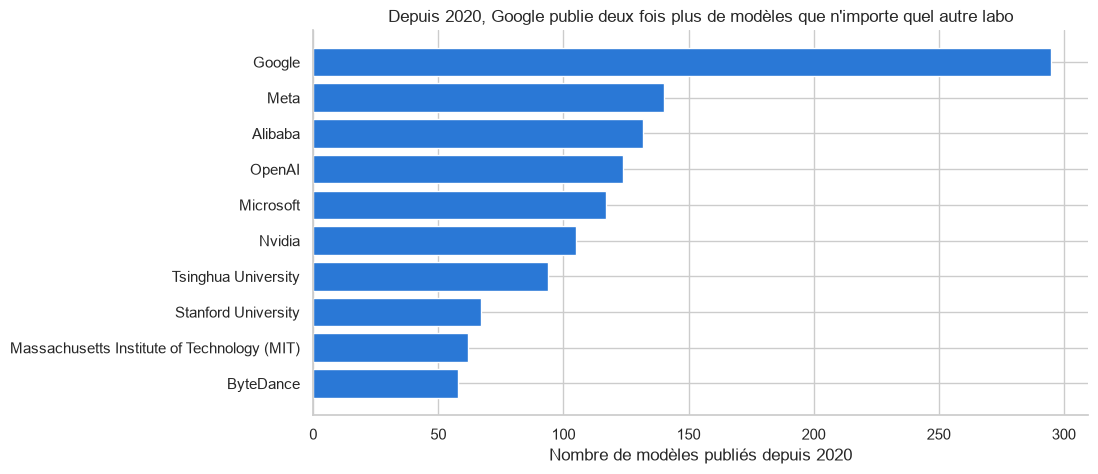

In [15]:
top_organisations = modeles_par_organisation.head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_organisations.index, top_organisations.values, color=BLEU)
ax.set_title("Depuis 2020, Google publie deux fois plus de modèles que n'importe quel autre labo")
ax.set_xlabel("Nombre de modèles publiés depuis 2020")
ax.set_ylabel(None)
fig.savefig("../figures/modeles_par_organisation.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
acces_connu = modeles_recents[modeles_recents["model_accessibility"] != "Inconnu"]
poids_ouverts_par_annee = acces_connu.groupby(acces_connu["publication_date"].dt.year).agg(
    modeles=("model_name", "size"),
    part_poids_ouverts=("open_model_weights", lambda reponses: (reponses == "Yes").mean() * 100),
)

poids_ouverts_par_annee.round(1)

,modeles,part_poids_ouverts
publication_date,,
2020,111,45.9
2021,194,40.7
2022,208,50.5
2023,450,59.8
2024,696,57.9
2025,540,56.3
2026,160,38.1


**Courbe** : l'évolution d'une part dans le temps. Les modèles dont l'accès est inconnu sont écartés du calcul.

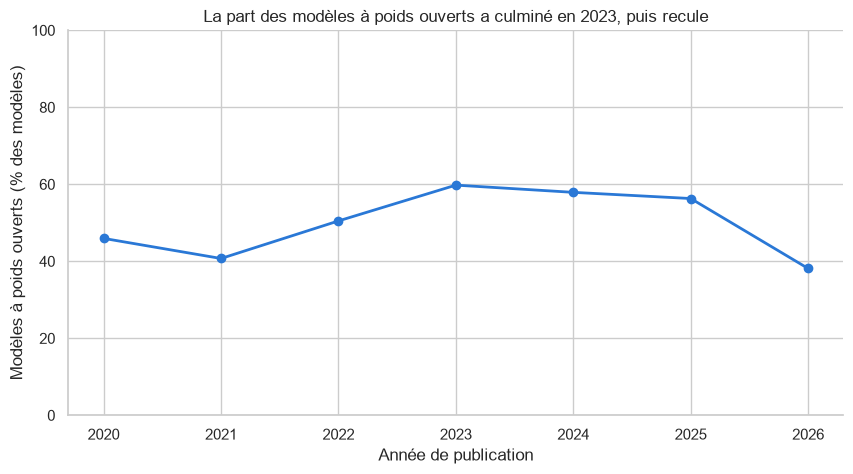

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(poids_ouverts_par_annee.index, poids_ouverts_par_annee["part_poids_ouverts"], color=BLEU, linewidth=2, marker="o")
ax.set_title("La part des modèles à poids ouverts a culminé en 2023, puis recule")
ax.set_xlabel("Année de publication")
ax.set_ylabel("Modèles à poids ouverts (% des modèles)")
ax.set_ylim(0, 100)
fig.savefig("../figures/poids_ouverts.png", dpi=150, bbox_inches="tight")
plt.show()

**Réponse** : depuis 2020, Google (295 modèles, toutes entités réunies) publie plus de deux fois plus que Meta (140), suivi d'Alibaba, OpenAI, Microsoft et Nvidia. Les universités Tsinghua, Stanford et le MIT sont les seules institutions académiques du top 10. Côté pays, les États-Unis dominent (1 417 modèles), devant la Chine (864), loin devant le Royaume-Uni (172) et la France (117), portée par Mistral AI (43 modèles) et le laboratoire parisien de Meta (37).

La part des modèles à poids ouverts n'a pas progressé régulièrement : elle passe de 46 % en 2020 à un pic de 60 % en 2023 (l'année de Llama), puis recule à 56 % en 2025 et 38 % en 2026. Ce dernier chiffre est à prendre avec prudence : l'année n'est pas finie, et les poids d'un modèle sont parfois publiés plusieurs mois après son annonce.

## 5. À quelle vitesse la puissance de calcul des modèles augmente-t-elle d'une année à l'autre ?

La puissance de calcul d'entraînement n'est connue que pour 1 410 modèles sur 3 614 : la réponse porte sur ceux-là. Elle va de 40 à 10²⁷ FLOP : on travaille sur son logarithme. Une droite ajustée sur le logarithme donne une croissance multiplicative constante : une pente de 0,6 par an veut dire « multipliée par 10⁰·⁶ ≈ 4 chaque année ».

In [18]:
compute_connu = modeles.dropna(subset=["training_compute_flop"]).copy()
compute_connu["annee_decimale"] = compute_connu["publication_date"].dt.year + compute_connu["publication_date"].dt.dayofyear / 365.25
compute_connu["log_compute"] = np.log10(compute_connu["training_compute_flop"])

tendances = {}
for nom, periode in [("Avant 2010", compute_connu["annee_decimale"] < 2010), ("Depuis 2010", compute_connu["annee_decimale"] >= 2010)]:
    sous_ensemble = compute_connu[periode]
    pente, origine = np.polyfit(sous_ensemble["annee_decimale"], sous_ensemble["log_compute"], 1)
    tendances[nom] = (pente, origine, sous_ensemble["annee_decimale"].min(), sous_ensemble["annee_decimale"].max())
    print(f"{nom} : {len(sous_ensemble)} modèles, multipliée par {10 ** pente:.1f} chaque année, doublement tous les {12 * np.log10(2) / pente:.0f} mois")

Avant 2010 : 75 modèles, multipliée par 1.5 chaque année, doublement tous les 20 mois
Depuis 2010 : 1335 modèles, multipliée par 3.9 chaque année, doublement tous les 6 mois


**Nuage de points** : chaque modèle est un point, la date en abscisse et la puissance de calcul en ordonnée, sur une échelle logarithmique. Les deux droites montrent la tendance de chaque période.

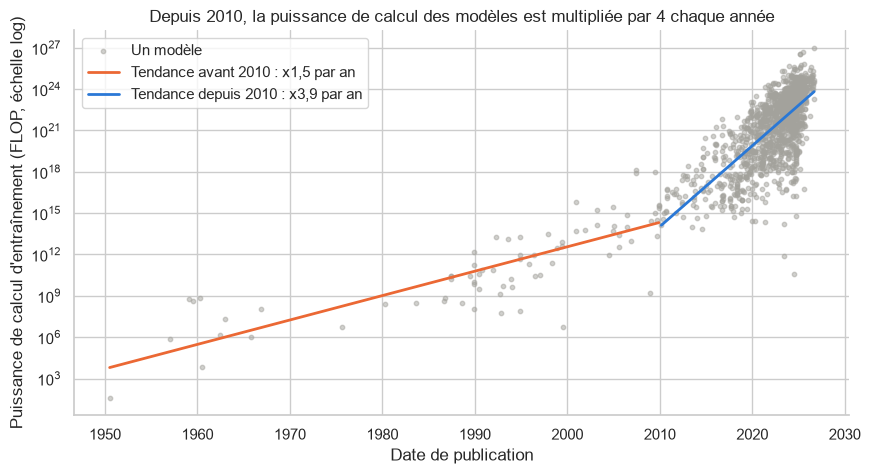

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(compute_connu["publication_date"], compute_connu["training_compute_flop"], s=10, color=GRIS, alpha=0.5, label="Un modèle")
for (nom, (pente, origine, debut, fin)), couleur in zip(tendances.items(), [ORANGE, BLEU]):
    annees = np.linspace(debut, fin, 50)
    dates = pd.to_datetime((annees - 1970) * 365.25, unit="D")
    ax.plot(dates, 10 ** (pente * annees + origine), color=couleur, linewidth=2, label=f"Tendance {nom.lower()} : x{10 ** pente:.1f} par an".replace(".", ","))
ax.set_yscale("log")
ax.set_title("Depuis 2010, la puissance de calcul des modèles est multipliée par 4 chaque année")
ax.set_xlabel("Date de publication")
ax.set_ylabel("Puissance de calcul d'entraînement (FLOP, échelle log)")
ax.legend()
fig.savefig("../figures/puissance_de_calcul.png", dpi=150, bbox_inches="tight")
plt.show()

**Réponse** : très vite, et de plus en plus vite. De 1950 à 2009, la puissance de calcul utilisée pour entraîner les modèles était multipliée par 1,5 chaque année, un doublement tous les 20 mois environ, proche du rythme de la loi de Moore. Depuis 2010 et l'essor de l'apprentissage profond, elle est multipliée par 3,9 chaque année, un doublement tous les 6 mois. Les modèles de 2026 ont été entraînés avec environ 10²⁷ FLOP, environ vingt milliards de fois plus que les meilleurs modèles de 2010.

## Conclusions

1. **L'IA a envahi Hacker News après ChatGPT.** Sa part dans les articles populaires passe de 1,5 % avant novembre 2022 à 9,4 % après, avec un record de 15,7 % en février 2026.
2. **Les articles sur l'IA font davantage débattre, mais depuis 2024 seulement.** Ils étaient moins commentés que les autres en 2020-2021 ; ils reçoivent en 2026 162 commentaires médians contre 113.
3. **Seules les grandes sorties de modèles font réagir Hacker News, et le jour même.** Environ un tiers d'articles sur l'IA en plus le jour d'une sortie majeure ; aucun effet pour l'ensemble des sorties.
4. **Google domine la production de modèles, et les États-Unis devant la Chine.** La part des modèles à poids ouverts a culminé à 60 % en 2023 avant de reculer.
5. **La puissance de calcul est multipliée par 4 chaque année depuis 2010**, contre 1,5 avant.

## Limites

- Hacker News ne garde ici que les articles ayant dépassé 100 points : c'est une vue des sujets populaires, pas de tout ce qui est publié. 2026 s'arrête au 24 avril.
- Un article « sur l'IA » est repéré par des mots-clés dans son titre : les titres qui en parlent sans les nommer sont manqués, et quelques faux positifs restent possibles.
- Les dates de publication d'Epoch AI ne sont pas toujours celles de la mise à disposition, ce qui brouille l'analyse au jour près de la question 3.
- Puissance de calcul et accès aux poids ne sont connus que pour une partie des modèles, surtout pour les modèles ouverts : les tendances des questions 4 et 5 portent sur les modèles documentés.
- Le regroupement des organisations ne couvre que les grands groupes (Google, Meta, Microsoft, Alibaba) ; les autres libellés restent tels quels.